# 875. Koko Eating Bananas
**Difficulty:** 🟡 Medium · **Topic:** Binary Search · **Pattern:** [Search on Answer](README.md) · **LeetCode:** https://leetcode.com/problems/koko-eating-bananas/

## 💡 Concepts

**Core concept(s):** **Binary search on the answer** — the array is not sorted and we never search inside it. Instead we binary-search the *range of possible answers* (eating speeds `1 … max(piles)`), using a yes/no **feasibility check** to decide which half to keep.

**Why it applies here:**
- The question asks for the **minimum** speed that still lets Koko finish within `h` hours: "smallest value that works".
- Feasibility is **monotonic**: if speed `k` finishes in time, every faster speed `k+1, k+2, …` also finishes in time (each pile takes the same or fewer hours).
- So the speeds line up as `no, no, …, no, YES, YES, …, YES`. We want the first `YES`, and binary search finds a boundary in a sorted yes/no line in `O(log M)` checks.

**Key intuition:**
- Checking one speed is easy: add up the hours each pile needs at that speed.
- Trying every speed is slow when piles are huge (up to `10^9`).
- Each check tells us which side of the boundary the speed lies on, so half the remaining speeds can be thrown away per check.

---

### 📚 What is Binary Search?
- **Binary search** finds a target in a **sorted** range by looking at the middle and discarding the half that cannot contain the answer.
- **Mental picture:** guessing a number between 1 and 100 with "higher / lower" hints. Each guess halves the range: 100 → 50 → 25 → … → 1 in about 7 guesses.
- **Complexity:** a range of size `M` shrinks to one value in `⌈log₂ M⌉` steps → **O(log M)** steps.
- **In Python:** plain integers `lo`, `hi`, `mid = (lo + hi) // 2` (Python ints never overflow; in Java/C++ write `lo + (hi - lo) // 2`). The stdlib `bisect` module does the same on a sorted list.

### 📚 What is Binary Search on the Answer?
- Instead of searching an array, you search the **set of candidate answers** — here the integers `1 … max(piles)`.
- You need a **feasibility check** `feasible(x) -> bool` ("can Koko finish at speed `x`?").
- The check must be **monotonic**: once it turns `True`, it stays `True` for every larger `x`.
- **Template (find the smallest `x` that works):** keep `lo < hi`; if `feasible(mid)` the answer is `mid` or smaller → `hi = mid`; otherwise it is bigger → `lo = mid + 1`. When `lo == hi`, that is the answer.
- **Complexity:** `O(log M)` checks × the cost of one check (`O(n)` here) → **O(n log M)**.

### 📚 What is Ceiling Division?
- `ceil(p / k)` = hours to finish a pile of `p` bananas eating `k` per hour (a partial last hour still costs a full hour).
- **Integer trick:** `(p + k - 1) // k` gives the ceiling using integers only — no floats, no rounding errors on values near `10^9`.
- Example: `p = 7, k = 3` → `(7 + 2) // 3 = 3` hours (3 + 3 + 1 bananas).
- **In Python:** `(p + k - 1) // k`, or `-(-p // k)`. Avoid `math.ceil(p / k)`: it goes through floats.

### 📚 What is a Linear Scan (brute force)?
- Try candidates one by one, in order, and stop at the first that works.
- **Complexity:** up to `M` candidates × `O(n)` per check → **O(n·M)**. Correct, but `M` can be `10^9`.

---

**Prerequisite knowledge:**
- Classic binary search on a sorted array (`lo`, `hi`, `mid`).
- Integer division `//` in Python.

## 📝 Problem

Koko has `n` piles of bananas; pile `i` has `piles[i]` bananas. The guards return in `h` hours.

Koko picks an eating speed `k` (bananas per hour). Each hour she chooses **one** pile and eats `k` bananas from it. If the pile has fewer than `k` bananas, she eats all of it and **does not** start another pile that hour.

Return the **minimum integer `k`** such that she can eat every banana within `h` hours.

**Example 1**
```
piles = [3, 6, 7, 11], h = 8  ->  4

speed 4:  3 -> 1h,  6 -> 2h,  7 -> 2h,  11 -> 3h   total 8h  <= 8  ok
speed 3:  3 -> 1h,  6 -> 2h,  7 -> 3h,  11 -> 4h   total 10h >  8  too slow
```

**Example 2**
```
piles = [30, 11, 23, 4, 20], h = 5  ->  30     (one hour per pile: speed must be the biggest pile)
```

**Example 3**
```
piles = [30, 11, 23, 4, 20], h = 6  ->  23
```

**Constraints:** `1 <= piles.length <= 10^4`, `piles.length <= h <= 10^9`, `1 <= piles[i] <= 10^9`.

> Two meaningfully distinct approaches: try every speed in order (`O(n·M)`, `M = max(piles)`), then binary search the speed (`O(n log M)`). A "better" middle step (starting the scan at `⌈sum/h⌉`) does not change the worst case, so it is not a separate approach.

In [1]:
from typing import List

def hours_needed(piles: List[int], k: int) -> int:
    """Hours Koko needs to finish every pile at speed k (the feasibility check's cost: O(n))."""
    return sum((p + k - 1) // k for p in piles)    # ceil(p / k) per pile, integers only

### Approach 1 — Brute Force: try every speed from 1 upward

**Idea:**
1. For `k = 1, 2, 3, …`, compute `hours_needed(piles, k)`.
2. Return the first `k` whose total is `<= h`. Speeds are tried in increasing order, so the first one that works is the minimum.
3. `k = max(piles)` always works (one hour per pile, and `h >= len(piles)`), so the loop always returns by then.

**Time complexity:** `O(n·M)` — up to `M = max(piles)` speeds, each check sums over `n` piles. With `M` up to `10^9` this times out.

**Space complexity:** `O(1)` — only the loop counter and a running sum.

In [2]:
def min_eating_speed_brute(piles: List[int], h: int) -> int:
    for k in range(1, max(piles) + 1):         # every candidate speed, slowest first
        if hours_needed(piles, k) <= h:        # first speed that fits in h hours...
            return k                           # ...is the minimum, since we go in increasing order
    return max(piles)                          # unreachable when h >= len(piles); kept for safety

### Approach 2 — Binary Search on the Answer (optimal · pattern template)

**Idea:** the [Search on Answer](README.md) template with `feasible(k) = hours_needed(piles, k) <= h`.
1. The answer lies in `[1, max(piles)]`: speed 1 is the slowest possible, and `max(piles)` always works.
2. Look at the middle speed `mid`.
   - If Koko finishes in time at `mid`, the answer is `mid` **or smaller** → `hi = mid` (keep `mid`, it might be the answer).
   - Otherwise `mid` is too slow, and so is every slower speed → `lo = mid + 1`.
3. When `lo == hi` the range holds one speed: the smallest one that works.

**Time complexity:** `O(n log M)` — `⌈log₂ M⌉` checks (about 30 for `M = 10^9`), each `O(n)`.

**Space complexity:** `O(1)` — just `lo`, `hi`, `mid`.

In [3]:
def min_eating_speed_binary(piles: List[int], h: int) -> int:
    lo, hi = 1, max(piles)                     # bounds of the ANSWER (speeds), not of the array
    while lo < hi:                             # stop when one candidate is left
        mid = (lo + hi) // 2
        if hours_needed(piles, mid) <= h:      # feasible: mid works...
            hi = mid                           # ...so the answer is mid or smaller (keep mid)
        else:
            lo = mid + 1                       # too slow: the answer is strictly bigger than mid
    return lo                                  # lo == hi == smallest feasible speed

In [4]:
# Correctness check
import random

tests = [
    (([3, 6, 7, 11], 8),         4),    # LeetCode example 1
    (([30, 11, 23, 4, 20], 5),   30),   # LeetCode example 2: h == len(piles) -> max(piles)
    (([30, 11, 23, 4, 20], 6),   23),   # LeetCode example 3
    (([1], 1),                   1),    # smallest input
    (([1000000000], 2),          500000000),  # one huge pile, two hours
    (([5, 5, 5], 1000),          1),    # lots of time: slowest speed already works
    (([312884470], 312884469),   2),    # one pile, h just below the pile size
]
for (piles, h), exp in tests:
    got = min_eating_speed_binary(piles, h)
    print(f"piles={str(piles):24} h={h:<10} -> {got}")
    assert got == exp, f"binary: {piles}, {h}: got {got}, expected {exp}"
    if max(piles) <= 10**6:            # brute force is only practical for small piles
        assert min_eating_speed_brute(piles, h) == exp, (piles, h)

# Randomised cross-check: both approaches must agree on many small inputs
rng = random.Random(875)
for _ in range(500):
    piles = [rng.randint(1, 60) for _ in range(rng.randint(1, 8))]
    h = rng.randint(len(piles), 3 * sum(piles) // 2 + len(piles))
    assert min_eating_speed_brute(piles, h) == min_eating_speed_binary(piles, h), (piles, h)
print("500 random inputs: both approaches agree")

print("\nAll tests passed")

piles=[3, 6, 7, 11]            h=8          -> 4
piles=[30, 11, 23, 4, 20]      h=5          -> 30
piles=[30, 11, 23, 4, 20]      h=6          -> 23
piles=[1]                      h=1          -> 1
piles=[1000000000]             h=2          -> 500000000
piles=[5, 5, 5]                h=1000       -> 1
piles=[312884470]              h=312884469  -> 2
500 random inputs: both approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing size and read the **doubling ratio** — how much runtime grows when the input doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(log n)`    | ≈ **1×** |
| `O(n)` / `O(n log n)` | ≈ **2×** (a little over for `n log n`) |
| `O(n²)`       | ≈ **4×** |

Both approaches depend on two sizes: `n` piles and `M = max(piles)`. The worst-case input below grows **both together**: `piles = [1, 2, …, n]` and `h = n`. With `h = n` Koko gets one hour per pile, so the answer is `M = n` itself — the brute force must try **every** speed before it succeeds.
- Brute force `O(n·M)` becomes `O(n²)` → expect ≈ **4×**.
- Binary search `O(n log M)` becomes `O(n log n)` → expect ≈ **2×**.


brute O(n*M)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      250 |       1.43 |           n/a
      500 |       6.74 |         4.72x
     1000 |      27.14 |         4.03x


     2000 |     110.43 |         4.07x

binary O(n log M)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      250 |       0.05 |           n/a
      500 |       0.11 |         2.44x
     1000 |       0.25 |         2.23x
     2000 |       0.56 |         2.20x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


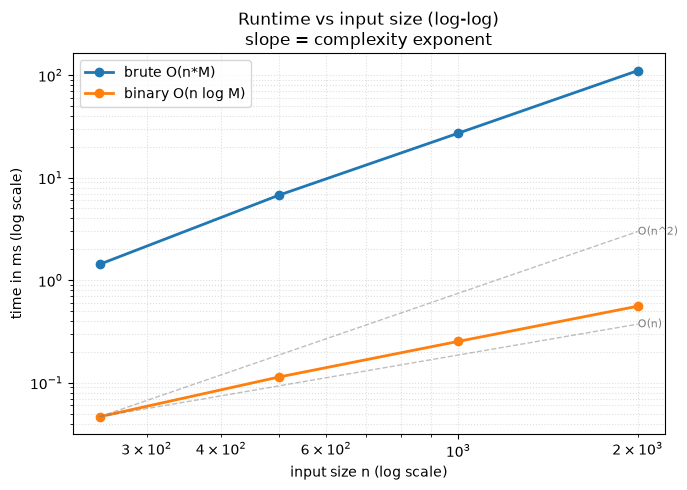

{'brute O(n*M)': [1.4269580133259296,
  6.741542019881308,
  27.14079211000353,
  110.42654106859118],
 'binary O(n log M)': [0.04658394027501345,
  0.11366698890924454,
  0.2530000638216734,
  0.5573329981416464]}

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    return (list(range(1, n + 1)), n)       # max(piles) = n and h = n -> the answer is n, the last speed tried
solutions = {
    "brute O(n*M)": min_eating_speed_brute,
    "binary O(n log M)": min_eating_speed_binary,
}
sizes = [250, 500, 1000, 2000]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Search on Answer](README.md) — binary-search the eating speed in `[1, max(piles)]`; the feasibility check is "total hours at this speed `<= h`".
- **Binary search does not need a sorted array — it needs a monotonic yes/no question.** If "`x` works" implies "`x + 1` works", the candidates form `no … no YES … YES`, and binary search finds the first `YES`.
- **Template for "smallest x that works":** `lo, hi = smallest possible, largest needed`; `while lo < hi`: `mid = (lo + hi) // 2`; `feasible(mid)` → `hi = mid`, else `lo = mid + 1`; return `lo`.
- **Bounds come from the problem, not the array:** the slowest sensible speed is `1`; the fastest you ever need is `max(piles)` (one hour per pile).
- **Ceiling division with integers:** `(p + k - 1) // k`.
- **Signal:** "minimum speed / capacity / days / size such that … within `h` / `D` / `m`", "minimize the maximum", "maximize the minimum", huge value ranges (`10^9`) next to a small `n`.
- **Related problems (same template, different check):** Capacity To Ship Packages Within D Days (LC 1011), Split Array Largest Sum (LC 410), Minimum Number of Days to Make m Bouquets (LC 1482), Find the Smallest Divisor Given a Threshold (LC 1283).
- **Common pitfalls:**
  1. Using `hi = mid - 1` when `mid` is feasible — it can skip the answer. Feasible `mid` might *be* the answer, so keep it: `hi = mid`.
  2. Starting `lo` at `0` — speed `0` divides by zero in the check.
  3. `math.ceil(p / k)` with floats — integer `(p + k - 1) // k` is exact.
  4. Searching indices of `piles` instead of speeds — the array is never sorted or searched.